# Customer Review (CR) dataset — baselines, CNN-rand and transfer from MR

This notebook reproduces the CR column of Kim (2014), Table 2, with 10-fold cross-validation: TF-IDF + logistic regression, NBSVM (paper 81.8 %) and CNN-rand (paper 79.8 %). It then trains the same models on the movie reviews (MR) and tests them on CR, as a first test of our transfer hypothesis.

## 0 · Install dependencies

We install the pinned versions from `requirements.txt` so the results are reproducible.

In [ ]:
import sys, subprocess
from pathlib import Path
REQ = next(p / "requirements.txt" for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets==5.1.0", "gensim==4.4.0"], check=True)
else:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REQ)], check=True)

## 1 · Load the CR dataset

We load `SetFit/CR` from Hugging Face — a copy of the customer-review data collected by Hu & Liu (2004) at cs.uic.edu. We print the dataset object to see the split names, the columns and how many rows each split has, then we merge all splits into one DataFrame (the paper used cross-validation over all sentences, so we do the same).

In [2]:
from datasets import load_dataset
import pandas as pd

cr = load_dataset("SetFit/CR")
print(cr)                       # shows the split names, columns and sizes
df = pd.concat([cr[s].to_pandas() for s in cr.keys()], ignore_index=True)
print(df.columns.tolist())
print(df.head())

README.md:   0%|          | 0.00/255 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl:   0%|          | 0.00/493k [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/52.1k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3394 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/376 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 3394
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 376
    })
})
['text', 'label', 'label_text']
                                                text  label label_text
0  player works and looks great if you can get th...      1   positive
1                                        what a junk      0   negative
2  as the 6600 uses 900mhz , it operates in more ...      1   positive
3  i find this feature on this phone useless , bu...      0   negative
4  i have found that the interface on the nomad i...      1   positive


## 2 · Size check against the paper + class balance

Kim (2014) Table 1 lists CR with **N = 3,775**, average length **19** words and vocabulary **|V| = 5,340**. We compare our downloaded copy with those numbers. Small differences are fine — we just want to know and report what we found. We also check the class balance: unlike the movie-review data, CR is **not** balanced, so we must look at macro-F1 and the majority-class floor, not only accuracy. Finally we confirm the label mapping (0 = negative, 1 = positive).

In [5]:
TEXT, LABEL = "text", "label"
PAPER_N = 3775
print("Per split:", {s: len(cr[s]) for s in cr.keys()})
print(f"Total: {len(df)}  (paper Table 1: {PAPER_N}, diff = {len(df) - PAPER_N})")
print("Avg words/sentence:", df[TEXT].str.split().str.len().mean())   # paper: 19
print("Vocabulary size:", len({w for t in df[TEXT] for w in t.lower().split()}))  # paper: 5340
print(df[LABEL].value_counts())   # CR is NOT balanced (more positive)
print(df.groupby(LABEL)["label_text"].first())   # confirm 0=neg, 1=pos

Per split: {'train': 3394, 'test': 376}
Total: 3770  (paper Table 1: 3775, diff = -5)
Avg words/sentence: 19.120954907161803
Vocabulary size: 5331
label
1    2405
0    1365
Name: count, dtype: int64
label
0    negative
1    positive
Name: label_text, dtype: object


## 3 · Cleaning

We drop rows with missing text or label, then count and remove exact duplicates. This matters more than usual here: with cross-validation, a duplicated sentence can land in both the training and the test fold and leak. We also count *conflicting* labels — the same text appearing with both labels — so we can report it.

In [6]:
n0 = len(df)
df = df.dropna(subset=[TEXT, LABEL])
n_dup = df.duplicated(subset=[TEXT]).sum()
conflicting = df.groupby(TEXT)[LABEL].nunique().gt(1).sum()   # same text, different labels
df = df.drop_duplicates(subset=[TEXT, LABEL]).reset_index(drop=True)
print(f"Rows before {n0}, duplicates {n_dup}, conflicting labels {conflicting}, after {len(df)}")

Rows before 3770, duplicates 5, conflicting labels 0, after 3765


## 4 · Class balance plot

A quick bar chart of the two classes, saved to `figures/`. It documents the imbalance we report in the write-up.

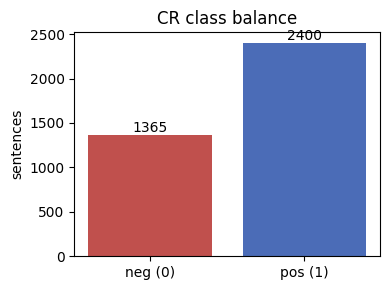

In [7]:
import matplotlib.pyplot as plt
from pathlib import Path

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "README.md").exists())
(REPO_ROOT / "figures").mkdir(exist_ok=True)

counts = df[LABEL].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(["neg (0)", "pos (1)"], counts.values, color=["#c0504d", "#4b6cb7"])
ax.set_ylabel("sentences")
ax.set_title("CR class balance")
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
fig.tight_layout()
fig.savefig(REPO_ROOT / "figures" / "cr_class_balance.png", dpi=150)
plt.show()

## 5 · Baseline 1 — TF-IDF + logistic regression (10-fold CV)

Our first baseline is a word-level TF-IDF (uni- + bigrams) feeding a logistic regression — the professor's "step 1" baseline.

Two deliberate choices:

- **10-fold stratified cross-validation** over *all* cleaned sentences. That is what the paper did (CR has no official split), and CR is small so a single split would give a noisy number. We report mean ± std over the folds.
- **No stop-word removal** (unlike the movie notebook). English stop-word lists delete words like *not* and *no*, which carry sentiment. Keeping them costs nothing here.

The whole pipeline (vectoriser + classifier) is fitted inside each fold on the training part only, so nothing leaks.

In [8]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

X, y = df[TEXT].astype(str), df[LABEL].to_numpy(dtype=int)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

logreg = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1)),
    ("clf", LogisticRegression(C=1.0, max_iter=2000, random_state=42)),
])
lr_res = cross_validate(logreg, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
print(f"LogReg acc {lr_res['test_accuracy'].mean():.4f} ± {lr_res['test_accuracy'].std():.4f}")
print(f"LogReg macro-F1 {lr_res['test_f1_macro'].mean():.4f} ± {lr_res['test_f1_macro'].std():.4f}")

LogReg acc 0.7849 ± 0.0168
LogReg macro-F1 0.7394 ± 0.0224


## 6 · Baseline 2 — NBSVM (10-fold CV)

NBSVM (Wang & Manning, 2012) is the strong bag-of-words baseline Kim compared against; on CR the paper reports **81.8 %**. It reweights binary count features by the log-count ratio between the positive and negative class, then trains a linear SVM. Here it is wrapped as a small scikit-learn estimator so the vectoriser, the ratios and the SVM are all fitted inside each training fold. `min_df=2` from the movie notebook is dropped because CR is small. Parameters are fixed — nothing is tuned on the test folds.

In [9]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC

class NBSVM(BaseEstimator, ClassifierMixin):
    def __init__(self, C=0.1, alpha=1.0, class_weight=None):
        self.C, self.alpha, self.class_weight = C, alpha, class_weight
    def fit(self, X, y):
        self.vec_ = CountVectorizer(binary=True, ngram_range=(1, 2))
        Xb = self.vec_.fit_transform(X)
        p = np.asarray(Xb[y == 1].sum(0)).ravel() + self.alpha
        q = np.asarray(Xb[y == 0].sum(0)).ravel() + self.alpha
        self.r_ = np.log((p / p.sum()) / (q / q.sum()))
        self.svm_ = LinearSVC(C=self.C, max_iter=5000, random_state=42, class_weight=self.class_weight).fit(Xb.multiply(self.r_).tocsr(), y)
        self.classes_ = self.svm_.classes_
        return self
    def predict(self, X):
        return self.svm_.predict(self.vec_.transform(X).multiply(self.r_).tocsr())

nb_res = cross_validate(NBSVM(), X, y, cv=cv, scoring=["accuracy", "f1_macro"])
print(f"NBSVM acc {nb_res['test_accuracy'].mean():.4f} ± {nb_res['test_accuracy'].std():.4f}")
print(f"NBSVM macro-F1 {nb_res['test_f1_macro'].mean():.4f} ± {nb_res['test_f1_macro'].std():.4f}")

NBSVM acc 0.8016 ± 0.0193
NBSVM macro-F1 0.7668 ± 0.0233


## 7 · Results table + majority floor

We collect the 10 fold scores of both models into one CSV (`results/cr_baseline_cv.csv`) and print the mean ± std.

Because CR is imbalanced we also compute the **majority-class floor**: the accuracy of a "model" that always predicts the positive class. Any real model must beat this number; it is the honest reference for our accuracy.

In [10]:
rows = []
for name, res, paper in [("tfidf_logreg", lr_res, None), ("nbsvm", nb_res, 81.8)]:
    for fold, (a, f) in enumerate(zip(res["test_accuracy"], res["test_f1_macro"])):
        rows.append({"model": name, "fold": fold, "accuracy": a, "f1_macro": f, "paper_accuracy": paper})
out = pd.DataFrame(rows)
(REPO_ROOT / "results").mkdir(exist_ok=True)
out.to_csv(REPO_ROOT / "results" / "cr_baseline_cv.csv", index=False)
display(out.groupby("model")[["accuracy", "f1_macro"]].agg(["mean", "std"]))

# Majority-class floor: per fold (share of the bigger class in each test fold) and overall
floors = []
for _, test_idx in cv.split(X, y):
    floors.append(np.bincount(y[test_idx]).max() / len(test_idx))
print(f"Majority floor (always predict pos): {np.mean(floors):.4f} mean over folds; {y.mean():.4f} overall")

accuracy            f1_macro          
                  mean       std      mean       std
model                                               
nbsvm         0.801582  0.020329  0.766847  0.024593
tfidf_logreg  0.784854  0.017671  0.739378  0.023636

Majority floor (always predict pos): 0.6375 mean over folds; 0.6375 overall


## 8 · Confusion matrix

`cross_val_predict` gives one out-of-fold prediction per sentence for the logistic-regression baseline, so the confusion matrix below summarises all 10 test folds at once. We pass `display_labels=["neg", "pos"]` explicitly so the axes are in the right order.

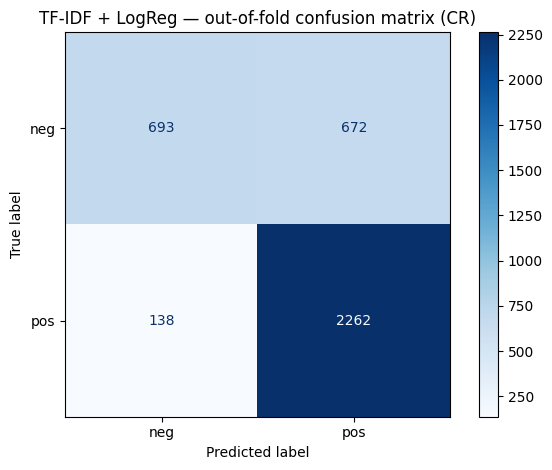

In [11]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

y_pred = cross_val_predict(logreg, X, y, cv=cv)
cm = confusion_matrix(y, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["neg", "pos"])
disp.plot(cmap=plt.cm.Blues)
plt.title("TF-IDF + LogReg — out-of-fold confusion matrix (CR)")
fig = plt.gcf()
fig.tight_layout()
fig.savefig(REPO_ROOT / "figures" / "cr_confusion_logreg.png", dpi=150)
plt.show()

## 9 · CNN-rand — building blocks

Kim's CNN in one line per step:

- **Embedding:** each word becomes a 300-d vector. For CNN-rand the vectors start random (uniform in [-0.25, 0.25]) and are learned.
- **Convolution:** filters of width 3, 4 and 5 (100 each) slide over the sentence, like n-gram detectors.
- **Max-over-time pooling:** each filter keeps only its strongest response → 300 features per sentence.
- **Dropout 0.5 → softmax:** the classifier. After every update, softmax weight rows with an L2 norm above 3 are rescaled to 3 (max-norm).
- **Training:** Adadelta, batch 50, 25 epochs; we keep the epoch with the best dev accuracy (early stopping). Adadelta's ρ = 0.95, ε = 1e-6 and the 25 epochs come from Kim's released code; the paper only says "Adadelta" and "early stopping".

In [13]:
import re, random, copy
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

def clean_str(s):   # Kim (2014) tokenizer, from his released code
    s = re.sub(r"[^A-Za-z0-9(),!?\'\`]", " ", s)
    for a in ["'s", "'ve", "n't", "'re", "'d", "'ll"]:
        s = s.replace(a, " " + a)
    s = re.sub(r"([,!?()])", r" \1 ", s)
    return re.sub(r"\s{2,}", " ", s).strip().lower().split()

PAD, UNK = 0, 1
def build_vocab(token_lists):
    return {w: i + 2 for i, w in enumerate(sorted({w for t in token_lists for w in t}))}

def encode(token_lists, vocab, max_len, pad=4):   # pad = max filter width - 1, as in Kim
    out = np.zeros((len(token_lists), max_len + 2 * pad), dtype=np.int64)
    for i, t in enumerate(token_lists):
        ids = [vocab.get(w, UNK) for w in t][:max_len]
        out[i, pad:pad + len(ids)] = ids
    return out

class KimCNN(nn.Module):
    def __init__(self, vocab_size, emb_dim=300, widths=(3, 4, 5), n_filters=100, dropout=0.5):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        nn.init.uniform_(self.emb.weight, -0.25, 0.25)
        with torch.no_grad(): self.emb.weight[PAD].zero_()
        self.convs = nn.ModuleList(nn.Conv1d(emb_dim, n_filters, w) for w in widths)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(n_filters * len(widths), 2)
    def forward(self, x):
        e = self.emb(x).transpose(1, 2)
        h = torch.cat([F.relu(c(e)).max(dim=2).values for c in self.convs], dim=1)
        return self.fc(self.drop(h))

def predict(model, X, bs=500):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(torch.from_numpy(X[i:i+bs]).to(DEVICE)).argmax(1).cpu()
                          for i in range(0, len(X), bs)]).numpy()

def predict_proba(model, X, bs=500):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(torch.from_numpy(X[i:i+bs]).to(DEVICE)).softmax(1).cpu()
                          for i in range(0, len(X), bs)]).numpy()

def train_cnn(Xtr, ytr, Xdev, ydev, vocab_size, epochs=25, bs=50, seed=42, model=None, class_weight=None):
    set_seed(seed)
    model = (model if model is not None else KimCNN(vocab_size)).to(DEVICE)
    opt = torch.optim.Adadelta(model.parameters(), lr=1.0, rho=0.95, eps=1e-6)
    Xt, yt = torch.from_numpy(Xtr), torch.from_numpy(ytr)
    best_acc, best_state = -1.0, None
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(perm), bs):
            idx = perm[i:i+bs]
            w = (torch.tensor(class_weight, dtype=torch.float32, device=DEVICE) if class_weight is not None else None)
            loss = F.cross_entropy(model(Xt[idx].to(DEVICE)), yt[idx].to(DEVICE), weight=w)
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():   # max-norm 3 on softmax weight rows
                model.fc.weight.copy_(torch.renorm(model.fc.weight, 2, 0, 3.0))
        dev_acc = accuracy_score(ydev, predict(model, Xdev))
        if dev_acc > best_acc:      # early stopping = keep best-dev epoch
            best_acc, best_state = dev_acc, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, best_acc

Device: cuda


## 10 · CNN-rand — 10-fold CV on CR

Same 10 folds as the baselines (`cv` from section 5), so the numbers are directly comparable. Inside each training part, 10 % is held out as a dev set; we keep the epoch with the best dev accuracy (early stopping, Kim §3.1). The vocabulary is built from the training part only, which is stricter than Kim's code (he used all sentences); words seen only in the test fold become `UNK`. Hyperparameters are fixed to the paper's: widths 3/4/5 × 100 filters, dropout 0.5, max-norm 3, batch 50, Adadelta (ρ = 0.95, ε = 1e-6), 25 epochs. Paper: **79.8 %**.

In [ ]:
tokens = df[TEXT].map(clean_str).tolist()
y = df[LABEL].to_numpy(dtype=np.int64)
MAX_LEN = max(map(len, tokens))

cnn_rows = []
for fold, (tr, te) in enumerate(cv.split(X, y)):          # same folds as the baselines
    tr, dev = train_test_split(tr, test_size=0.1, stratify=y[tr], random_state=fold)
    vocab = build_vocab([tokens[i] for i in tr])          # vocab from the training part only
    enc = lambda idx: encode([tokens[i] for i in idx], vocab, MAX_LEN)
    model, dev_acc = train_cnn(enc(tr), y[tr], enc(dev), y[dev], len(vocab) + 2, seed=fold)
    p = predict(model, enc(te))
    cnn_rows.append({"model": "cnn_rand", "fold": fold, "accuracy": accuracy_score(y[te], p),
                     "f1_macro": f1_score(y[te], p, average="macro"), "paper_accuracy": 79.8})
    print(f"fold {fold}: dev {dev_acc:.4f}  test {cnn_rows[-1]['accuracy']:.4f}")

cnn_df = pd.DataFrame(cnn_rows)
cnn_df.to_csv(REPO_ROOT / "results" / "cr_cnn_rand_cv.csv", index=False)
all_cv = pd.concat([out, cnn_df], ignore_index=True)
display(all_cv.groupby("model")[["accuracy", "f1_macro"]].agg(["mean", "std"]))

fold 0: dev 0.8053  test 0.7772


fold 1: dev 0.8112  test 0.7984


fold 2: dev 0.8289  test 0.7984


fold 3: dev 0.8083  test 0.7958


fold 4: dev 0.8024  test 0.7851


fold 5: dev 0.8496  test 0.7952


fold 6: dev 0.7729  test 0.7633


fold 7: dev 0.8407  test 0.7899


fold 8: dev 0.8142  test 0.7952


fold 9: dev 0.8201  test 0.8112


accuracy            f1_macro          
                  mean       std      mean       std
model                                               
cnn_rand      0.790969  0.013201  0.767583  0.015591
nbsvm         0.801582  0.020329  0.766847  0.024593
tfidf_logreg  0.784854  0.017671  0.739378  0.023636

## 11 · Train on MR, test on CR (zero-shot transfer)

We train each model on **all** movie-review sentences (MR, 10,662, Pang & Lee 2005) and never show it a CR label. We then score it on the **same 10 CR test folds** as above, so the numbers sit side by side and allow a paired test.

Two effects should lower accuracy compared with training on CR:

- **Domain shift:** movie words ("plot", "acting") vs product words ("battery", "zoom"). We print how many CR tokens have no entry in the MR vocabulary.
- **Prior shift:** MR is 50/50, CR is 64 % positive. That is why we report macro-F1 next to accuracy.

TF-IDF and NBSVM are fitted on MR only, so CR-only words are ignored. The CNN uses the MR vocabulary (CR-only words → `UNK`), 10 % of MR as dev for early stopping, and 3 seeds because there is only one training set. The MR-trained weights are saved for the next step (pretrain on MR, fine-tune on CR).

In [ ]:
from sklearn.base import clone

mr = pd.concat([pd.read_parquet(f"hf://datasets/cornell-movie-review-data/rotten_tomatoes/{s}.parquet")
                for s in ["train", "validation", "test"]], ignore_index=True)
mr = mr.dropna(subset=["text", "label"]).drop_duplicates(subset=["text", "label"]).reset_index(drop=True)
X_mr, y_mr = mr["text"].astype(str), mr["label"].to_numpy(dtype=np.int64)
print(len(mr), mr["label"].value_counts().to_dict())
print("MR ∩ CR identical sentences:", len(set(X_mr.str.lower()) & set(X.str.lower())))

def per_fold(name, p_all, seed=None):
    return [{"model": name, "setting": "MR→CR", "seed": seed, "fold": f,
             "accuracy": accuracy_score(y[te], p_all[te]), "f1_macro": f1_score(y[te], p_all[te], average="macro")}
            for f, (_, te) in enumerate(cv.split(X, y))]

transfer_rows = []
for name, est in [("tfidf_logreg", logreg), ("nbsvm", NBSVM())]:
    transfer_rows += per_fold(name, clone(est).fit(X_mr, y_mr).predict(X))

mr_tokens = mr["text"].map(clean_str).tolist()
mr_vocab = build_vocab(mr_tokens)
print(f"CR tokens without an MR vocab entry: {np.mean([w not in mr_vocab for t in tokens for w in t]):.1%}")
L = max(MAX_LEN, max(map(len, mr_tokens)))
X_mr_enc, X_cr_enc = encode(mr_tokens, mr_vocab, L), encode(tokens, mr_vocab, L)
tr, dev = train_test_split(np.arange(len(mr)), test_size=0.1, stratify=y_mr, random_state=0)
for seed in [0, 1, 2]:                                    # 1 training set → 3 seeds for a spread
    model, dev_acc = train_cnn(X_mr_enc[tr], y_mr[tr], X_mr_enc[dev], y_mr[dev], len(mr_vocab) + 2, seed=seed)
    print(f"seed {seed}: MR dev {dev_acc:.4f}")
    torch.save(model.state_dict(), REPO_ROOT / "results" / f"cnn_rand_mr_seed{seed}.pt")  # reused for fine-tuning
    transfer_rows += per_fold("cnn_rand", predict(model, X_cr_enc), seed)

tr_df = pd.DataFrame(transfer_rows)
tr_df.to_csv(REPO_ROOT / "results" / "cr_transfer_mr.csv", index=False)

10662 {1: 5331, 0: 5331}
MR ∩ CR identical sentences: 0


CR tokens without an MR vocab entry: 8.5%


seed 0: MR dev 0.7863


seed 1: MR dev 0.7648


seed 2: MR dev 0.7648


## 12 · Comparison — in-domain CV vs MR→CR

Mean ± std over the 10 CR test folds for each model and setting (for the CNN, the 3 seeds are first averaged per fold). The Wilcoxon signed-rank test compares the two settings fold by fold; this is valid because both use exactly the same test folds.

In [ ]:
from scipy.stats import wilcoxon

in_dom = all_cv.assign(setting="CR 10-fold CV")
xfer = tr_df.groupby(["model", "setting", "fold"], as_index=False)[["accuracy", "f1_macro"]].mean()  # avg seeds per fold
summary = pd.concat([in_dom, xfer]).groupby(["model", "setting"])[["accuracy", "f1_macro"]].agg(["mean", "std"])
display(summary.round(4))

for m in ["tfidf_logreg", "nbsvm", "cnn_rand"]:
    a = in_dom.query("model == @m").sort_values("fold")["accuracy"].to_numpy()
    b = xfer.query("model == @m").sort_values("fold")["accuracy"].to_numpy()
    print(f"{m}: CV {a.mean():.4f} vs MR→CR {b.mean():.4f}, Wilcoxon p = {wilcoxon(a, b).pvalue:.4f}")

accuracy         f1_macro        
                               mean     std     mean     std
model        setting                                        
cnn_rand     CR 10-fold CV   0.7910  0.0132   0.7676  0.0156
             MR→CR           0.6390  0.0146   0.6359  0.0140
nbsvm        CR 10-fold CV   0.8016  0.0203   0.7668  0.0246
             MR→CR           0.6282  0.0131   0.6269  0.0133
tfidf_logreg CR 10-fold CV   0.7849  0.0177   0.7394  0.0236
             MR→CR           0.6391  0.0160   0.6375  0.0160

tfidf_logreg: CV 0.7849 vs MR→CR 0.6391, Wilcoxon p = 0.0020
nbsvm: CV 0.8016 vs MR→CR 0.6282, Wilcoxon p = 0.0020
cnn_rand: CV 0.7910 vs MR→CR 0.6390, Wilcoxon p = 0.0020


## 13 · Ablation — class imbalance and MR fine-tuning

CR is imbalanced (more positive than negative), so we test two standard fixes — **class-weighted loss** and **oversampling the minority class** — and we also try **fine-tuning the MR-pretrained CNN** on CR instead of training from random embeddings. We keep the same 10 folds, the same train/dev split per fold, and run every CNN variant with seeds 0–2.

In [ ]:
from sklearn.metrics import recall_score, make_scorer

variants = ["cnn_rand", "cnn_rand_classweight", "cnn_rand_oversample",
            "cnn_mr_finetune", "cnn_mr_finetune_oversample"]
abl_rows, oof_rows = [], []

for fold, (tr0, te) in enumerate(cv.split(X, y)):
    tr, dev = train_test_split(tr0, test_size=0.1, stratify=y[tr0], random_state=fold)  # same split as §10
    # balance the TRAINING part only: oversample negatives up to the positive count
    neg = tr[y[tr] == 0]
    tr_bal = np.concatenate([tr, np.random.default_rng(fold).choice(neg, (y[tr] == 1).sum() - len(neg))])
    cw = len(tr) / (2 * np.bincount(y[tr]))           # sklearn-style class weights

    vocab = build_vocab([tokens[i] for i in tr])      # same as §10
    vocab_ft = dict(mr_vocab)                          # MR vocab + unseen CR words appended
    for w in sorted({w for i in tr for w in tokens[i]} - set(mr_vocab)):
        vocab_ft[w] = len(vocab_ft) + 2

    for seed in [0, 1, 2]:
        for name in variants:
            ft = name.startswith("cnn_mr")
            v = vocab_ft if ft else vocab
            tr_idx = tr_bal if name.endswith("oversample") else tr
            enc = lambda idx: encode([tokens[i] for i in idx], v, MAX_LEN)
            if ft:
                set_seed(seed)
                model = KimCNN(len(vocab_ft) + 2)
                state = torch.load(REPO_ROOT / "results" / f"cnn_rand_mr_seed{seed}.pt", map_location="cpu")
                with torch.no_grad():   # keep MR rows; new CR rows keep Kim's U[-0.25, 0.25] init
                    model.emb.weight[:len(mr_vocab) + 2] = state["emb.weight"]
                res = model.load_state_dict({k: vv for k, vv in state.items() if k != "emb.weight"}, strict=False)
                assert res.missing_keys == ["emb.weight"], res
            else:
                model = None
            model, dev_acc = train_cnn(enc(tr_idx), y[tr_idx], enc(dev), y[dev], len(v) + 2,
                                       seed=seed, model=model,
                                       class_weight=cw if name.endswith("classweight") else None)
            p = predict(model, enc(te))
            abl_rows.append({"model": name, "seed": seed, "fold": fold,
                             "accuracy": accuracy_score(y[te], p),
                             "f1_macro": f1_score(y[te], p, average="macro"),
                             "neg_recall": recall_score(y[te], p, pos_label=0),
                             "dev_acc": dev_acc})
            print(f"fold {fold} seed {seed} {name}: dev {dev_acc:.4f}  test {abl_rows[-1]['accuracy']:.4f}")
            if seed == 0:
                for i, pp in zip(te, predict_proba(model, enc(te))[:, 1]):
                    oof_rows.append({"idx": i, "model": name, "y_true": y[i], "p_pos": pp})

# sklearn baselines on the same folds, plain and class-balanced
scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro",
           "neg_recall": make_scorer(recall_score, pos_label=0)}
for name, est in [("tfidf_logreg", logreg),
                  ("tfidf_logreg_balanced", clone(logreg).set_params(clf__class_weight="balanced")),
                  ("nbsvm", NBSVM()),
                  ("nbsvm_balanced", NBSVM(class_weight="balanced"))]:
    res = cross_validate(clone(est), X, y, cv=cv, scoring=scoring)
    for fold in range(10):
        abl_rows.append({"model": name, "seed": np.nan, "fold": fold,
                         "accuracy": res["test_accuracy"][fold],
                         "f1_macro": res["test_f1_macro"][fold],
                         "neg_recall": res["test_neg_recall"][fold],
                         "dev_acc": np.nan})
    print(f"{name}: acc {res['test_accuracy'].mean():.4f}")

abl_df = pd.DataFrame(abl_rows)
abl_df.to_csv(REPO_ROOT / "results" / "cr_ablation_cv.csv", index=False)
pd.DataFrame(oof_rows).to_csv(REPO_ROOT / "results" / "cr_oof_seed0.csv", index=False)


fold 0 seed 0 cnn_rand: dev 0.8083  test 0.7666


fold 0 seed 0 cnn_rand_classweight: dev 0.8142  test 0.7984


fold 0 seed 0 cnn_rand_oversample: dev 0.8112  test 0.8064


fold 0 seed 0 cnn_mr_finetune: dev 0.7935  test 0.7745


fold 0 seed 0 cnn_mr_finetune_oversample: dev 0.7965  test 0.7719


fold 0 seed 1 cnn_rand: dev 0.8171  test 0.7958


... (144 outputs left out)

tfidf_logreg: acc 0.7849


tfidf_logreg_balanced: acc 0.7976


nbsvm: acc 0.8016


nbsvm_balanced: acc 0.8122


## 14 · Ablation table + paired tests

We average the three seeds per fold, report mean ± sample SD over the 10 folds, and run paired tests (paired *t* and Wilcoxon) on the fold-level differences against `cnn_rand` and within each balanced/unbalanced pair.

In [ ]:
from scipy.stats import ttest_rel

fold_mean = abl_df.groupby(["model", "fold"], as_index=False)[["accuracy", "f1_macro", "neg_recall"]].mean()
summary = fold_mean.groupby("model").agg(
    accuracy_mean=("accuracy", "mean"), accuracy_sd=("accuracy", "std"),
    f1_macro_mean=("f1_macro", "mean"), f1_macro_sd=("f1_macro", "std"),
    neg_recall_mean=("neg_recall", "mean"), neg_recall_sd=("neg_recall", "std"),
    n_seeds=("accuracy", "size")).sort_values("accuracy_mean", ascending=False)
# majority floor: always predict positive
maj_f1 = np.mean([f1_score(y[te], np.ones(len(te), dtype=int), average="macro")
                  for _, te in cv.split(X, y)])
summary.loc["majority_floor"] = [0.6375, np.nan, maj_f1, np.nan, 0.0, np.nan, np.nan]
summary.to_csv(REPO_ROOT / "results" / "cr_ablation_summary.csv")
display((summary.drop(columns="n_seeds") * 100).round(1).assign(n_seeds=summary["n_seeds"]))

pairs = [(m, "cnn_rand") for m in variants[1:]] + [
    ("cnn_mr_finetune_oversample", "cnn_mr_finetune"),
    ("tfidf_logreg_balanced", "tfidf_logreg"),
    ("nbsvm_balanced", "nbsvm")]
test_rows = []
for a, b in pairs:
    for metric in ["accuracy", "f1_macro"]:
        va = fold_mean.query("model == @a").sort_values("fold")[metric].to_numpy()
        vb = fold_mean.query("model == @b").sort_values("fold")[metric].to_numpy()
        d = va - vb
        try:
            w_p = wilcoxon(va, vb).pvalue
        except ValueError:
            w_p = np.nan
        test_rows.append({"model_a": a, "model_b": b, "metric": metric,
                          "mean_diff_pp": d.mean() * 100, "sd_diff_pp": d.std(ddof=1) * 100,
                          "wins": int((d > 0).sum()),
                          "ttest_p": ttest_rel(va, vb).pvalue, "wilcoxon_p": w_p})
tests_df = pd.DataFrame(test_rows)
tests_df.to_csv(REPO_ROOT / "results" / "cr_paired_tests.csv", index=False)
display(tests_df.round(4))


,accuracy_mean,accuracy_sd,f1_macro_mean,f1_macro_sd,neg_recall_mean,neg_recall_sd,n_seeds
model,,,,,,,
nbsvm_balanced,81.2,2.1,78.5,2.5,63.4,4.1,10.0
cnn_mr_finetune_oversample,80.7,1.4,78.9,1.6,71.1,3.4,10.0
cnn_mr_finetune,80.5,1.7,78.7,1.9,70.8,2.9,10.0
nbsvm,80.2,2.0,76.7,2.5,57.4,3.9,10.0
tfidf_logreg_balanced,79.8,2.2,78.5,2.3,76.5,3.9,10.0
cnn_rand_oversample,79.3,2.3,77.2,2.3,67.8,3.3,10.0
cnn_rand,79.1,1.9,76.8,2.2,65.9,5.0,10.0
cnn_rand_classweight,79.1,2.0,76.9,2.5,67.1,6.2,10.0
tfidf_logreg,78.5,1.8,73.9,2.4,50.8,3.8,10.0


,model_a,model_b,metric,mean_diff_pp,sd_diff_pp,wins,ttest_p,wilcoxon_p
0,cnn_rand_classweight,cnn_rand,accuracy,-0.0443,0.6528,4,0.8350,0.7578
1,cnn_rand_classweight,cnn_rand,f1_macro,0.0865,0.7871,6,0.7361,0.7695
2,cnn_rand_oversample,cnn_rand,accuracy,0.1686,0.9320,4,0.5814,0.9375
3,cnn_rand_oversample,cnn_rand,f1_macro,0.4131,1.1296,7,0.2773,0.3223
4,cnn_mr_finetune,cnn_rand,accuracy,1.3726,1.1561,9,0.0045,0.0039
5,cnn_mr_finetune,cnn_rand,f1_macro,1.8935,1.1560,10,0.0006,0.0020
6,cnn_mr_finetune_oversample,cnn_rand,accuracy,1.5496,1.1841,9,0.0025,0.0039
7,cnn_mr_finetune_oversample,cnn_rand,f1_macro,2.0842,1.3291,9,0.0008,0.0039
8,cnn_mr_finetune_oversample,cnn_mr_finetune,accuracy,0.1770,0.7889,5,0.4961,0.5566
9,cnn_mr_finetune_oversample,cnn_mr_finetune,f1_macro,0.1907,0.9333,5,0.5343,0.4922


## 15 · Error analysis — best CNN variant

We take the CNN variant with the highest mean CV accuracy, look at its seed-0 out-of-fold predictions, and inspect the mistakes it was most confident about.

Best CNN variant: cnn_mr_finetune_oversample


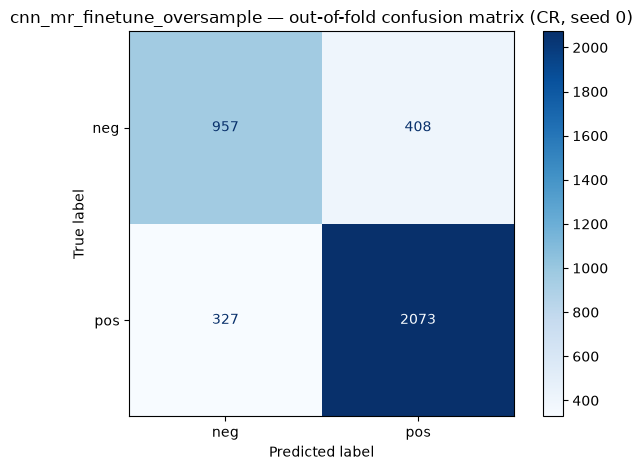

              precision    recall  f1-score   support

         neg       0.75      0.70      0.72      1365
         pos       0.84      0.86      0.85      2400

    accuracy                           0.80      3765
   macro avg       0.79      0.78      0.79      3765
weighted avg       0.80      0.80      0.80      3765

  true=neg  p_pos=1.000  |  on the plus side it ' s packed with features , including bluetooth that works fine it ' s really a tiny computer that is also a phone and that ' s the negative
  true=neg  p_pos=1.000  |  although the sd500 takes great quality photos , the sensitivity of the lcd compromises the quality overall
  true=neg  p_pos=1.000  |  i replaced it with a router raiser and it works much better
  true=neg  p_pos=1.000  |  if you think you are saving 40 getting the hitachi , you are right , and you are also getting a router worth 40 less than a makita
  true=neg  p_pos=1.000  |  this isn 't uncommon in cameras , though , just as long as you bring your c

1129

In [ ]:
from sklearn.metrics import classification_report

oof_df = pd.DataFrame(oof_rows)
best_cnn = fold_mean.query("model in @variants").groupby("model")["accuracy"].mean().idxmax()
print("Best CNN variant:", best_cnn)
o = oof_df.query("model == @best_cnn").sort_values("idx")
y_hat = (o["p_pos"] >= 0.5).astype(int)

cm = confusion_matrix(o["y_true"], y_hat)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["neg", "pos"]).plot(cmap=plt.cm.Blues)
plt.title(f"{best_cnn} — out-of-fold confusion matrix (CR, seed 0)")
fig = plt.gcf(); fig.tight_layout()
fig.savefig(REPO_ROOT / "figures" / "cr_confusion_best_cnn.png", dpi=150)
plt.show()
report = classification_report(o["y_true"], y_hat, target_names=["neg", "pos"])
print(report)

wrong = o[o["y_true"] != y_hat].assign(conf=lambda d: np.maximum(d["p_pos"], 1 - d["p_pos"]))
worst = wrong.sort_values("conf", ascending=False).head(5)
lines = [f"Best CNN variant: {best_cnn}", "", report, "", "Most confident wrong predictions:"]
for _, r in worst.iterrows():
    line = f"  true={'pos' if r.y_true else 'neg'}  p_pos={r.p_pos:.3f}  |  {df.loc[r.idx, TEXT]}"
    print(line)
    lines.append(line)
(REPO_ROOT / "results" / "cr_error_analysis.txt").write_text("\n".join(lines) + "\n")


## 16 · CNN-static and CNN-non-static (word2vec)

Kim's two pretrained variants (Table 2, CR: **84.7 %** static, **84.3 %** non-static). Each word starts from its 300-d GoogleNews word2vec vector (Mikolov et al. 2013, code.google.com/archive/p/word2vec, Apache 2.0). Words without a vector start random in U[-0.25, 0.25], as in Kim's code.

- **CNN-static:** the embedding layer is frozen. Only the filters and the classifier learn.
- **CNN-non-static:** the embeddings are fine-tuned together with the rest.

Everything else is the same as §10/§13: the same 10 folds, the same 10 % dev split (`random_state=fold`), seeds 0, 1 and 2, the vocabulary from the training part only, and Kim's hyperparameters (25 epochs, best-dev early stopping).

This section was run on a Colab T4 GPU. §10–§15 were not re-run there, so their stored outputs come from the earlier local run. §16 rebuilds `tokens`, `y` and `MAX_LEN` so it only needs §1–§9.


In [14]:
# %pip install -q gensim
import gensim, gensim.downloader as api
from sklearn.metrics import recall_score
print("gensim", gensim.__version__)

tokens = df[TEXT].map(clean_str).tolist()          # same as §10
y = df[LABEL].to_numpy(dtype=np.int64)
MAX_LEN = max(map(len, tokens))

w2v = api.load("word2vec-google-news-300")          # ≈1.7 GB download, 3M words × 300

w2v_rows = []
for fold, (tr0, te) in enumerate(cv.split(X, y)):   # same folds as §5–§13
    tr, dev = train_test_split(tr0, test_size=0.1, stratify=y[tr0], random_state=fold)  # same dev split as §13
    vocab = build_vocab([tokens[i] for i in tr])     # vocab from the training part only
    hits = {i: w2v[w] for w, i in vocab.items() if w in w2v.key_to_index}
    enc = lambda idx: encode([tokens[i] for i in idx], vocab, MAX_LEN)
    for seed in [0, 1, 2]:
        for name in ["cnn_static", "cnn_nonstatic"]:
            set_seed(seed)
            model = KimCNN(len(vocab) + 2)           # PAD row 0, others U[-0.25, 0.25]
            with torch.no_grad():                    # overwrite rows of words that have a word2vec vector
                idx = torch.tensor(list(hits.keys()))
                model.emb.weight[idx] = torch.from_numpy(np.stack(list(hits.values())))
            if name == "cnn_static":
                model.emb.weight.requires_grad_(False)   # frozen embeddings
            model, dev_acc = train_cnn(enc(tr), y[tr], enc(dev), y[dev], len(vocab) + 2, seed=seed, model=model)
            p = predict(model, enc(te))
            w2v_rows.append({"model": name, "seed": seed, "fold": fold,
                             "accuracy": accuracy_score(y[te], p),
                             "f1_macro": f1_score(y[te], p, average="macro"),
                             "neg_recall": recall_score(y[te], p, pos_label=0),
                             "dev_acc": dev_acc, "vocab": len(vocab), "in_w2v": len(hits)})
            print(f"fold {fold} seed {seed} {name}: dev {dev_acc:.4f}  test {w2v_rows[-1]['accuracy']:.4f}")

w2v_df = pd.DataFrame(w2v_rows)
w2v_df.to_csv(REPO_ROOT / "results" / "cr_word2vec_cv.csv", index=False)
cov = w2v_df.drop_duplicates("fold")
print(f"Vocabulary words with a word2vec vector: {cov['in_w2v'].mean():.0f} of {cov['vocab'].mean():.0f} "
      f"({(cov['in_w2v'] / cov['vocab']).mean():.1%}) per training part; paper Table 1: 5,046 of 5,340 (94.5 %)")
del w2v


gensim 4.4.0
[==================================================] 100.0% 1662.8/1662.8MB downloaded
fold 0 seed 0 cnn_static: dev 0.8319  test 0.8011
fold 0 seed 0 cnn_nonstatic: dev 0.8407  test 0.7878
fold 0 seed 1 cnn_static: dev 0.8348  test 0.8223
fold 0 seed 1 cnn_nonstatic: dev 0.8348  test 0.8196
fold 0 seed 2 cnn_static: dev 0.8378  test 0.8090
fold 0 seed 2 cnn_nonstatic: dev 0.8466  test 0.8196
fold 1 seed 0 cnn_static: dev 0.8437  test 0.8170
fold 1 seed 0 cnn_nonstatic: dev 0.8289  test 0.8249
fold 1 seed 1 cnn_static: dev 0.8466  test 0.8143
fold 1 seed 1 cnn_nonstatic: dev 0.8348  test 0.8196
fold 1 seed 2 cnn_static: dev 0.8437  test 0.8170
fold 1 seed 2 cnn_nonstatic: dev 0.8378  test 0.8064
fold 2 seed 0 cnn_static: dev 0.8643  test 0.8170
fold 2 seed 0 cnn_nonstatic: dev 0.8761  test 0.8329
fold 2 seed 1 cnn_static: dev 0.8850  test 0.7931
fold 2 seed 1 cnn_nonstatic: dev 0.8879  test 0.8170
fold 2 seed 2 cnn_static: dev 0.8673  test 0.8170
fold 2 seed 2 cnn_nonstati

## 17 · word2vec variants vs CNN-rand: table + paired tests

We average the 3 seeds per fold and report mean ± sample SD over the 10 folds. Then we compare each variant with CNN-rand fold by fold, using a paired t-test and a Wilcoxon signed-rank test.

The CNN-rand rows are read from `results/cr_ablation_cv.csv` (§13). Folds, dev splits, seeds and code are identical, but §13 ran on Apple MPS and §16 on a Colab T4, so small hardware noise (±0.1–0.3 pp) is possible.


In [15]:
from scipy.stats import ttest_rel, wilcoxon

base = pd.read_csv(REPO_ROOT / "results" / "cr_ablation_cv.csv").query("model == 'cnn_rand'")
cols = ["accuracy", "f1_macro", "neg_recall"]
fm = pd.concat([base[["model", "seed", "fold"] + cols], w2v_df[["model", "seed", "fold"] + cols]]) \
       .groupby(["model", "fold"], as_index=False)[cols].mean()
paper = {"cnn_rand": 79.8, "cnn_static": 84.7, "cnn_nonstatic": 84.3}
w2v_summary = (fm.groupby("model")[cols].agg(["mean", "std"]) * 100).round(1)
w2v_summary.columns = [f"{m}_{s}" for m, s in w2v_summary.columns]
w2v_summary["paper_accuracy"] = w2v_summary.index.map(paper)
w2v_summary["seeds_x_folds"] = "3 x 10"
w2v_summary.to_csv(REPO_ROOT / "results" / "cr_word2vec_summary.csv")
display(w2v_summary)

rows = []
for a, b in [("cnn_static", "cnn_rand"), ("cnn_nonstatic", "cnn_rand"), ("cnn_nonstatic", "cnn_static")]:
    for metric in ["accuracy", "f1_macro"]:
        va = fm.query("model == @a").sort_values("fold")[metric].to_numpy()
        vb = fm.query("model == @b").sort_values("fold")[metric].to_numpy()
        d = va - vb
        try:
            w_p = wilcoxon(va, vb).pvalue
        except ValueError:
            w_p = np.nan
        rows.append({"model_a": a, "model_b": b, "metric": metric,
                     "mean_diff_pp": d.mean() * 100, "sd_diff_pp": d.std(ddof=1) * 100,
                     "wins": int((d > 0).sum()), "ttest_p": ttest_rel(va, vb).pvalue, "wilcoxon_p": w_p})
w2v_tests = pd.DataFrame(rows)
w2v_tests.to_csv(REPO_ROOT / "results" / "cr_word2vec_paired.csv", index=False)
display(w2v_tests.round(4))


,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,neg_recall_mean,neg_recall_std,paper_accuracy,seeds_x_folds
model,,,,,,,,
cnn_nonstatic,83.2,1.5,81.7,1.7,75.7,3.5,84.3,3 x 10
cnn_rand,79.1,1.9,76.8,2.2,65.9,5.0,79.8,3 x 10
cnn_static,82.8,1.5,81.1,1.7,74.0,4.4,84.7,3 x 10


,model_a,model_b,metric,mean_diff_pp,sd_diff_pp,wins,ttest_p,wilcoxon_p
0,cnn_static,cnn_rand,accuracy,3.6407,2.1859,9,0.0005,0.0039
1,cnn_static,cnn_rand,f1_macro,4.3397,2.5786,9,0.0005,0.0039
2,cnn_nonstatic,cnn_rand,accuracy,4.0742,1.8862,10,0.0001,0.0020
3,cnn_nonstatic,cnn_rand,f1_macro,4.9197,2.1900,10,0.0001,0.0020
4,cnn_nonstatic,cnn_static,accuracy,0.4335,0.8598,6,0.1453,0.2031
5,cnn_nonstatic,cnn_static,f1_macro,0.5799,0.9518,7,0.0861,0.1309
